In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PORTFOLIO_VALUE = 1_000_000

weights = pd.Series({
    "SPY": 0.30,
    "QQQ": 0.20,
    "TLT": 0.25,
    "GLD": 0.15,
    "EURUSD=X": 0.10
})

In [2]:
stress_scenarios = pd.DataFrame({
    "Equity Selloff": {
        "SPY": -0.15,
        "QQQ": -0.20,
        "TLT": 0.05,
        "GLD": 0.04,
        "EURUSD=X": -0.03
    },

    "Rate Shock": {
        "SPY": -0.06,
        "QQQ": -0.08,
        "TLT": -0.12,
        "GLD": -0.04,
        "EURUSD=X": -0.02
    },

    "Risk-Off Flight": {
        "SPY": -0.10,
        "QQQ": -0.14,
        "TLT": 0.08,
        "GLD": 0.07,
        "EURUSD=X": -0.04
    },

    "Broad Market Stress": {
        "SPY": -0.12,
        "QQQ": -0.16,
        "TLT": -0.08,
        "GLD": -0.06,
        "EURUSD=X": -0.05
    }
}).T

stress_scenarios

,SPY,QQQ,TLT,GLD,EURUSD=X
Equity Selloff,-0.15,-0.20,0.05,0.04,-0.03
Rate Shock,-0.06,-0.08,-0.12,-0.04,-0.02
Risk-Off Flight,-0.10,-0.14,0.08,0.07,-0.04
Broad Market Stress,-0.12,-0.16,-0.08,-0.06,-0.05


In [3]:
stress_results = []

for scenario, shocks in stress_scenarios.iterrows():

    portfolio_return = (
        shocks * weights
    ).sum()

    portfolio_pnl = (
        portfolio_return
        * PORTFOLIO_VALUE
    )

    stress_results.append({
        "Scenario": scenario,
        "Portfolio_Return": portfolio_return,
        "Portfolio_PnL": portfolio_pnl
    })

stress_results = pd.DataFrame(
    stress_results
)

stress_results

,Scenario,Portfolio_Return,Portfolio_PnL
0,Equity Selloff,-0.0695,-69500.0
1,Rate Shock,-0.0720,-72000.0
2,Risk-Off Flight,-0.0315,-31500.0
3,Broad Market Stress,-0.1020,-102000.0


In [4]:
stress_results["Loss"] = (
    -stress_results["Portfolio_PnL"]
)

stress_results

,Scenario,Portfolio_Return,Portfolio_PnL,Loss
0,Equity Selloff,-0.0695,-69500.0,69500.0
1,Rate Shock,-0.0720,-72000.0,72000.0
2,Risk-Off Flight,-0.0315,-31500.0,31500.0
3,Broad Market Stress,-0.1020,-102000.0,102000.0


In [5]:
stress_results = stress_results.sort_values(
    "Portfolio_PnL"
)

stress_results

,Scenario,Portfolio_Return,Portfolio_PnL,Loss
3,Broad Market Stress,-0.1020,-102000.0,102000.0
1,Rate Shock,-0.0720,-72000.0,72000.0
0,Equity Selloff,-0.0695,-69500.0,69500.0
2,Risk-Off Flight,-0.0315,-31500.0,31500.0


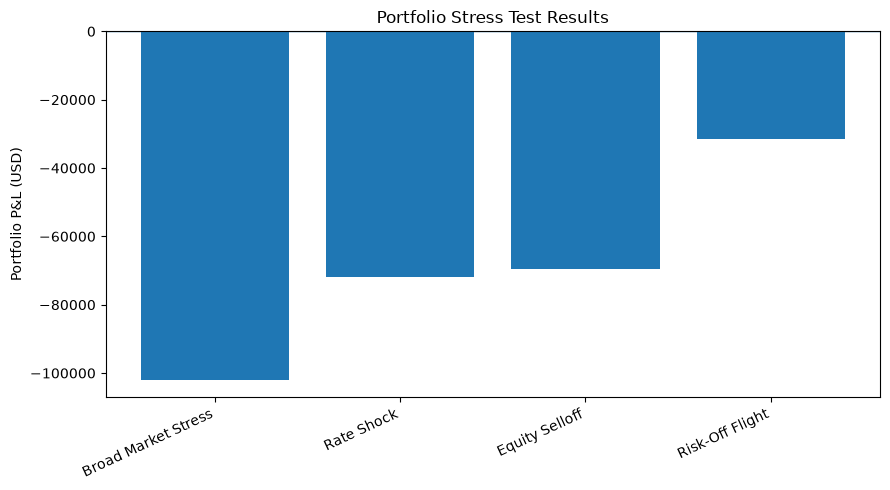

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(
    stress_results["Scenario"],
    stress_results["Portfolio_PnL"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.ylabel("Portfolio P&L (USD)")
plt.title("Portfolio Stress Test Results")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/stress_test_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
stress_results = stress_results.sort_values(
    "Portfolio_PnL"
)

stress_results

,Scenario,Portfolio_Return,Portfolio_PnL,Loss
3,Broad Market Stress,-0.1020,-102000.0,102000.0
1,Rate Shock,-0.0720,-72000.0,72000.0
0,Equity Selloff,-0.0695,-69500.0,69500.0
2,Risk-Off Flight,-0.0315,-31500.0,31500.0


In [8]:
risk_extremes = pd.DataFrame({
    "Risk Measure": [
        "Historical VaR 99%",
        "Historical ES 99%",
        "Worst Stress Scenario"
    ],
    "Loss_USD": [
        17850.975906,
        23881.241660,
        stress_results["Loss"].max()
    ]
})

risk_extremes

,Risk Measure,Loss_USD
0,Historical VaR 99%,17850.975906
1,Historical ES 99%,23881.241660
2,Worst Stress Scenario,102000.000000


In [9]:
risk_extremes["Loss_%_Portfolio"] = (
    risk_extremes["Loss_USD"] /
    PORTFOLIO_VALUE
)

risk_extremes

,Risk Measure,Loss_USD,Loss_%_Portfolio
0,Historical VaR 99%,17850.975906,0.017851
1,Historical ES 99%,23881.241660,0.023881
2,Worst Stress Scenario,102000.000000,0.102000


## Stress Testing Interpretation

The stress testing framework produced losses materially larger than the statistical VaR and Expected Shortfall estimates.

The most severe hypothetical scenario, Broad Market Stress, generated a portfolio loss of approximately $102,000, equivalent to 10.2% of portfolio value.

For comparison:

- Historical VaR 99% was approximately $17.9K
- Historical Expected Shortfall 99% was approximately $23.9K
- Worst Stress Scenario loss was approximately $102K

This highlights an important distinction between statistical risk measures and stress testing.

VaR and Expected Shortfall estimate risk based on observed or modeled distributions, while stress testing evaluates portfolio resilience under deliberately severe hypothetical market shocks.